In [1]:
import sys
sys.path.append('../../')

import matplotlib.pyplot as plt

# Import methods
import QGP.Defocusing.Methods as Def
import QGP.Focusing.Methods as Foc
from QGP.Soliton_Gen import *
from Utilities import *

import config

In [2]:
def _get_valid_refpoints(xmin, xmax):
    d = xmax - xmin
    ref1 = xmin + d / 4.
    ref2 = xmax - d / 4.
    return ref1, ref2

# Dark Soliton in $D_1$

In [3]:
# Function to invert
path_save = "Solitons/Dark_D1/"

def F_c_k(y, c, k):
    
    # Domain
    ymin = 0
    ymax = 1-c*c/2
    
    y = np.asarray(y)
    
    valid_mask = (y > ymin) & (y <= ymax)
    
    # Assign infinite to values outside the domain
    val = np.full_like(y, np.inf, dtype=np.float64)
    val[y > ymax] = -np.inf
    
    def f_c_k(y):
        sum_1 = 2 * np.sqrt(k) * np.arctan(np.sqrt(k) * np.sqrt((2-c*c-2*y)/(1-2*k+2*k*y)))
        sum_2 = 2 * np.sqrt((1-2*k)/(2-c*c)) * np.arctanh(np.sqrt(((1-2*k)*(2-c*c-2*y))/((2-c*c)*(1-2*k+2*k*y))))
        output = sum_1 + sum_2
        return output
    
    val[valid_mask] = f_c_k(y[valid_mask])
    
    return val

c = 0.7071067811865476 k = 0.08333333333333333
c = 0.7071067811865476 k = 0.16666666666666666
c = 0.7071067811865476 k = 0.25
c = 0.7071067811865476 k = 0.3333333333333333
c = 0.7071067811865476 k = 0.41666666666666663


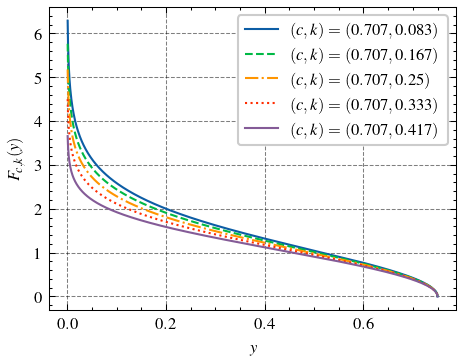

In [5]:
### Varying k ###

N = 6
c = np.sqrt(2)/2
ks = np.linspace(0, 1/2, N, endpoint=False)[1:]

y_to_plot = np.linspace(0, 1-c*c/2, 1_000)

for k in ks:
    print("c =", c, "k =", k)
    plt.plot(y_to_plot, F_c_k(y_to_plot, c, k), label=r"$(c, k)={}$".format((round(c, 3), round(k, 3))),
            marker="none")
    plt.legend()

plt.xlabel(r"$y$")
plt.ylabel(r"$F_{c, k}(y)$")

#plt.savefig(path_save+"Func_to_inv_ks.pdf", dpi=300, bbox_inches = "tight")
#plt.savefig(path_save+"Func_to_inv_ks.pgf", dpi=300, bbox_inches = "tight")
plt.show()

c = 0.0 k = 0.25
c = 0.282842712474619 k = 0.25
c = 0.565685424949238 k = 0.25
c = 0.848528137423857 k = 0.25
c = 1.131370849898476 k = 0.25


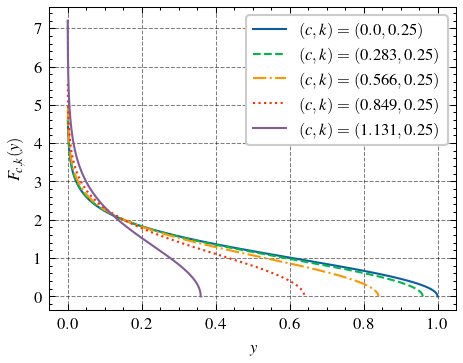

In [120]:
### Varying c ###

N = 5
cs = np.linspace(0, np.sqrt(2), N, endpoint=False)
k = 1/4

for c in cs:
    print("c =", c, "k =", k)
    y_to_plot = np.linspace(0, 1-c*c/2, 1_000)[1:]
    plt.plot(y_to_plot, F_c_k(y_to_plot, c, k), label=r"$(c, k)={}$".format((round(c, 3), round(k, 3))),
            marker="none")
    plt.legend()
    
plt.xlabel(r"$y$")
plt.ylabel(r"$F_{c, k}(y)$")
plt.savefig(path_save+"Func_to_inv_cs.pdf", dpi=300, bbox_inches = "tight")
plt.savefig(path_save+"Func_to_inv_cs.pgf", dpi=300, bbox_inches = "tight")
plt.show()

## Dark soliton

In [122]:
import warnings

## eta_c_k generator

def eta_c_k(x, c, k, x_0=0, even=True):
    
    # Domain
    ymin = 0
    ymax = 1-(c*c/2)
    
    ref1, ref2 = _get_valid_refpoints(ymin, ymax)
    
    min_kwargs = {}
    min_kwargs['bracket'] = (ref1, ref2)
    min_kwargs['tol'] = 1.48e-12
    min_kwargs['method'] = 'Golden'
    
    x = np.asarray(x)
    N = x.size
    m = N//2
    
    xpos = x[N//2:]
    
    F_to_inv = lambda y: F_c_k(y, c, k)-x_0
    
    results = np.full_like(x, np.nan, dtype=np.float64)
    resultsmask = np.zeros(x. shape, dtype=bool)
    
    for j in range(xpos.size):
        
        if F_to_inv(ymax) == xpos[j]: #is_close
            results[N//2+j] = ymax
        
        if F_to_inv(ymin) == xpos[j]:
            results[N//2+j] = ymin
        
        optimizer = (lambda x, j=j,
                        bounded_f=F_to_inv: (np.abs(F_to_inv(x) - xpos[j]))**2)
        
        try:
            with warnings.catch_warnings(record=True):
                result = minimize_scalar(optimizer, **min_kwargs)

            results[N//2+j] = result.x
            resultsmask[N//2+j] = result.success

        except:
            resultsmask[N//2+j] = False

    if any(~resultsmask[N//2:]):
            warnings.warn("Trouble calculating inverse for values: "
                          "%s" % str(xpos[~resultsmask[N//2:]]), RuntimeWarning)   
    try:
        np.testing.assert_array_almost_equal(xpos, F_to_inv(results[N//2:]), decimal=2)

    except AssertionError:
        warnings.warn("Results obtained with less than %g "
                          "decimal digits of accuracy"
                          % 2, RuntimeWarning)

    if even:
        if N%2 == 0:
            results[:N//2] = np.flip(results[N//2:])
        else:
            results[:N//2] = np.flip(results[N//2+1:])
        return results
    
    return results[N//2:]


c = 0.7071067811865476 k = 0.1
c = 0.7071067811865476 k = 0.2
c = 0.7071067811865476 k = 0.30000000000000004
c = 0.7071067811865476 k = 0.4


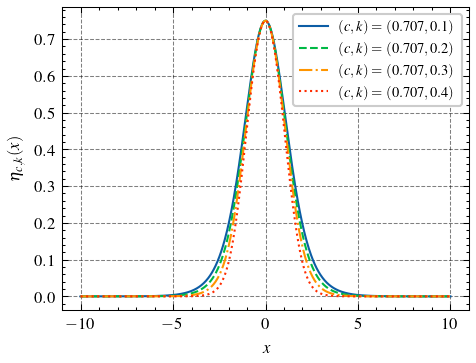

In [123]:
#import warnings
#warnings.filterwarnings("ignore")

### Invert function ###

### Varying k ###

N = 5
c = np.sqrt(2)/2
ks = np.linspace(0, 1/2, N, endpoint=False)[1:]

L = 10
x_0 = 0
x = np.linspace(-L, L, 1_001)-x_0

for k in ks:
    print("c =", c, "k =", k)
    plt.plot(x, eta_c_k(x, c, k, x_0=x_0), label=r"$(c, k)={}$".format((round(c, 3), round(k, 3))),
             marker="none")
    plt.legend(fontsize=7)

plt.xlabel(r"$x$")
plt.ylabel(r"$\eta_{c, k}(x)$")

plt.savefig(path_save+"eta_ks.pdf", dpi=300, bbox_inches = "tight")
plt.savefig(path_save+"eta_ks.pgf", dpi=300, bbox_inches = "tight")
plt.show()

c = 0.0 k = 0.25
c = 0.3535533905932738 k = 0.25
c = 0.7071067811865476 k = 0.25
c = 1.0606601717798214 k = 0.25


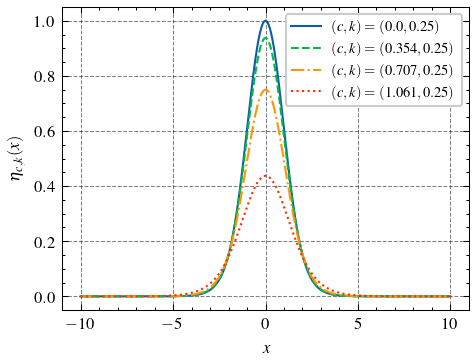

In [124]:
#import warnings
#warnings.filterwarnings("ignore")

### Invert function ###

### Varying k ###

N = 4
cs = np.linspace(0, np.sqrt(2), N, endpoint=False)
k = 1/4

L = 10
x_0 = 0
x = np.linspace(-L, L, 1_001)-x_0

for c in cs:
    print("c =", c, "k =", k)
    plt.plot(x, eta_c_k(x, c, k, x_0=x_0), label=r"$(c, k)={}$".format((round(c, 3), round(k, 3))), 
             marker="none")
    plt.legend(fontsize=7)

plt.xlabel(r"$x$")
plt.ylabel(r"$\eta_{c, k}(x)$")

plt.savefig(path_save+"eta_cs.pdf", dpi=300, bbox_inches = "tight")
plt.savefig(path_save+"eta_cs.pgf", dpi=300, bbox_inches = "tight")
plt.show()

In [125]:
print("c = ", c, "k = ", k)
Ns = np.array([2**(j) for j in range(2, 11)])
hs = []
errors = [] #np.zeros(len(Ns))
xs = []
L = 5

for j in range(len(Ns)):
    N = Ns[j]
    x = np.linspace(-L, L, N)
    eta = eta_c_k(x, c, k, even=False)
    
    x_pos = x[N//2:]
    h = x_pos[1] - x_pos[0]
    hs += [h]
    F_eta = F_c_k(eta, c, k)
    error = np.abs(x_pos - F_eta)
    
    errors += [error]
    xs += [x_pos]
    
hs = np.array(hs)

c =  1.0606601717798214 k =  0.25


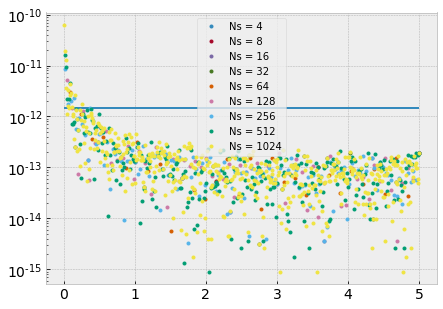

In [11]:
for j in range(len(errors)):
    plt.plot(xs[j], errors[j], ".", label="Ns = {}".format(Ns[j]))
#plt.plot(hs, hs**-0.8 * np.exp(-28))
plt.legend(fontsize=10)
plt.hlines(1.48e-12, 0, 5)
plt.yscale("log")
#plt.xscale("log")
plt.show()

In [12]:
print("c = ", c, "k = ", k)
Ns = np.array([2**(j) for j in range(2, 11)])
hs = []
errors = [] #np.zeros(len(Ns))
ys = []
L = 5

for j in range(len(Ns)):
    N = Ns[j]
    y = np.linspace(0, 1-c*c/2, N)[1:]
    F_ = F_c_k(y, c, k)
    F_ = np.append(np.flip(F_), F_)
    eta = eta_c_k(F_, c, k, even=False)
    error = np.abs(y - eta)
    
    errors += [error]
    ys += [y]
    
hs = np.array(hs)

c =  0.7071067811865476 k =  0.375


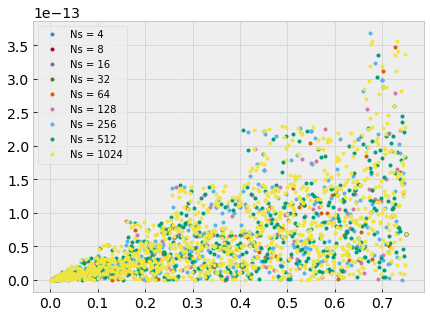

In [13]:
for j in range(len(errors)):
    plt.plot(ys[j], errors[j], ".", label="Ns = {}".format(Ns[j]))
#plt.plot(hs, hs**-0.8 * np.exp(-28))
plt.legend(fontsize=10)
#plt.hlines(1.48e-12, 0, 5)
#plt.yscale("log")
#plt.xscale("log")
plt.show()

c = [0.         0.35355339 0.70710678 1.06066017] k = 0.25


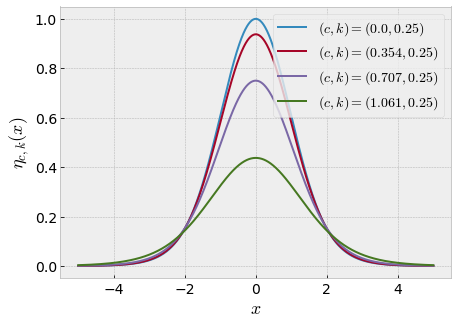

In [14]:
### Varying c ###

N = 4
cs = np.linspace(0, np.sqrt(2), N, endpoint=False)
k = 1/4
print("c =", cs, "k =", k)

L = 5
x = np.linspace(-L, L, 1_000)

for c in cs:
    
    plt.plot(x, eta_c_k(x, c, k), label=r"$(c, k)={}$".format((round(c, 3), round(k, 3))))
    plt.legend()

plt.xlabel(r"$x$")
plt.ylabel(r"$\eta_{c, k}(x)$")
plt.show()

## Checking ODE $\eta$ 

In [15]:
c = np.sqrt(2)/2
k = 1/4

L = 10
x = np.linspace(-L, L, 10_000)
h = x[1] - x[0]

eta = eta_c_k(x, c, k)
eta_prime = np.gradient(eta, h)
eta_prime_prime = np.gradient(eta_prime, h)

ODE = (1 - 2 * k + 2 * k * eta) * eta_prime_prime + k * eta_prime**2 + 3 * eta**2 - (2-c**2) * eta
ODE_2 = (1 - 2 * k + 2 * k * eta) * eta_prime**2 - (2 - c**2 - 2 * eta) * eta**2

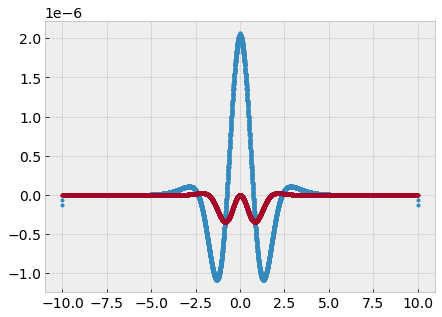

In [16]:
plt.plot(x, ODE, ".")
plt.plot(x, ODE_2, ".")

## $u$ variable

In [126]:
## Solitons in variable u

def rho_c_k(x, eta):
    output = np.sqrt(1 - eta)
    return output
    

def theta_c_k(x, c, eta):
    
    ## Function to integrate
    integrand = eta/(1 - eta)
    
    N = x.size
    m = N//2
    xpos = x[m:]
    theta = np.zeros(N)
    
    dx = xpos[1] - xpos[0]

    for j in range(xpos.size-1):
        
        theta[j+1+m] = theta[j+m] + c/2 * (dx/2 * (integrand[j+m] + integrand[j+m+1]))
        
    if N%2 == 0:
        theta[:m] = -np.flip(theta[m:])

    else:
        theta[:m] = -np.flip(theta[m+1:])
    
    return theta


def u_c_k(x, c, eta):
    i = 1j
    
    if c == 0:
        output = np.sign(x) * np.sqrt(1 - eta)
        return output
    
    rho = rho_c_k(x, eta)
    theta = theta_c_k(x, c, eta)
    return rho * np.exp(i*theta)

def norm(x):
    return np.abs(x)**2

c = 0.7071067811865476 k = 0.1
c = 0.7071067811865476 k = 0.2
c = 0.7071067811865476 k = 0.30000000000000004
c = 0.7071067811865476 k = 0.4


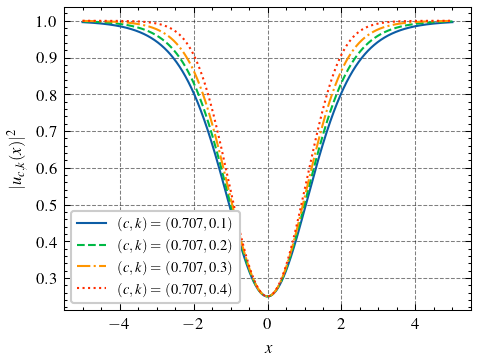

In [127]:
### Varying k ###

N = 5
c = np.sqrt(2)/2 #0
ks = np.linspace(0, 1/2, N, endpoint=False)[1:]


L = 5
x = np.linspace(-L, L, 2_001)


for k in ks:
    print("c =", c, "k =", k)
    eta = eta_c_k(x, c, k)
    plt.plot(x, norm(u_c_k(x, c, eta)), label=r"$(c, k)={}$".format((round(c, 3), round(k, 3))),
            marker="none")
    plt.legend(fontsize=7)

plt.xlabel(r"$x$")
plt.ylabel(r"$|u_{c, k}(x)|^2$")
plt.savefig(path_save+"D_1_dark_soliton_ks.pdf", dpi=300, bbox_inches = "tight")
plt.savefig(path_save+"D_1_dark_soliton_ks.pgf", dpi=300, bbox_inches = "tight")
plt.show()

c = [0.         0.35355339 0.70710678 1.06066017] k = 0.25


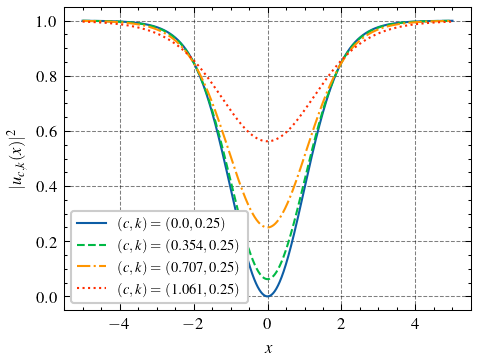

In [128]:
### Varying c ###

N = 4
cs = np.linspace(0, np.sqrt(2), N, endpoint=False)
k = 1/4
print("c =", cs, "k =", k)

L = 5
x = np.linspace(-L, L, 2_001)

for c in cs:
    eta = eta_c_k(x, c, k)
    plt.plot(x, norm(u_c_k(x, c, eta)), label=r"$(c, k)={}$".format((round(c, 3), round(k, 3))),
            marker="none")
    plt.legend(fontsize=7)

plt.xlabel(r"$x$")
plt.ylabel(r"$|u_{c, k}(x)|^2$")

plt.savefig(path_save+"D_1_dark_soliton_cs.pdf", dpi=300, bbox_inches = "tight")
plt.savefig(path_save+"D_1_dark_soliton_cs.pgf", dpi=300, bbox_inches = "tight")
plt.show()

## ODE $\theta$

In [20]:
c = np.sqrt(2)/2
k = 1/4

L = 10
x = np.linspace(-L, L, 10_001)
h = x[1] - x[0]

eta = eta_c_k(x, c, k)

theta = theta_c_k(x, c, eta)
theta_prime = np.gradient(theta, h, edge_order=2)
i = 1j

ODE_theta = theta_prime - c/2 * eta/(1 - eta)

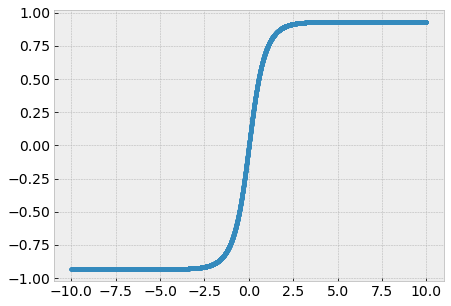

In [21]:
plt.plot(x, theta, ".")

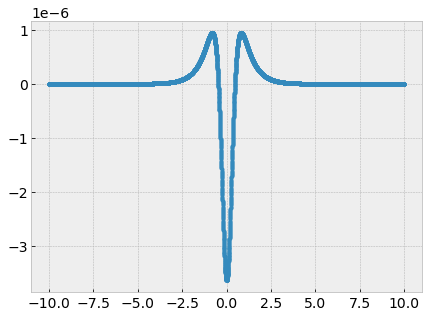

In [22]:
plt.plot(x, ODE_theta, ".")

In [23]:
eta[len(eta)//2], 1-c**2/2

(0.7499999999999318, 0.75)

## ODE $u$

In [24]:
c = np.sqrt(2)/2
k = 1/4

L = 10
x = np.linspace(-L, L, 10_000)
h = x[1] - x[0]

eta = eta_c_k(x, c, k)

u = u_c_k(x, c, eta)
u_prime = np.gradient(u, h)
u_prime_prime = np.gradient(u_prime, h)
norm_prime = np.gradient(1-np.abs(u)**2, h)
norm_prime_prime = np.gradient(norm_prime, h)
i = 1j

ODE_u = i * c * u_prime + u_prime_prime + u * (1 - np.abs(u)**2) + k * u * norm_prime_prime

ValueError: could not broadcast input array from shape (4999,) into shape (5000,)

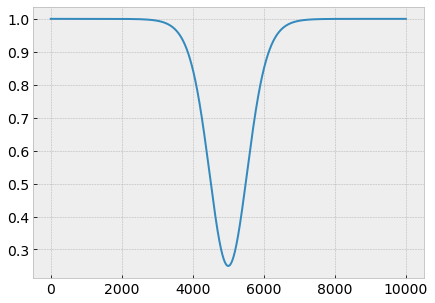

In [75]:
plt.plot(norm(u))

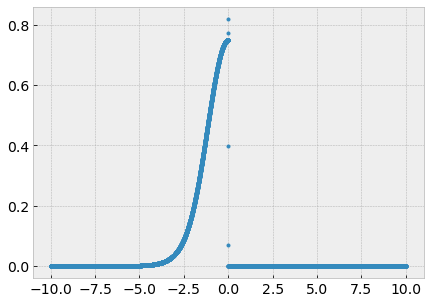

In [76]:
plt.plot(x, np.real(ODE_u), ".")

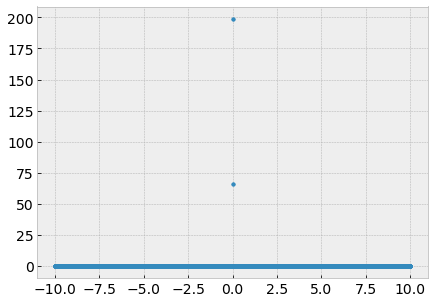

In [77]:
plt.plot(x, np.imag(ODE_u), ".")

# Dark Soliton in $D_2$

In [2]:
# Function to invert
path_save = "Solitons/Dark_D2/"
def G_c_k(y, c, k):
    
    # Domain
    ymin = 0
    ymax = 1-c*c/2
    
    y = np.asarray(y)
    
    valid_mask = (y > ymin) & (y <= ymax)
    
    # Assign infinite to values outside the domain
    val = np.full_like(y, np.inf, dtype=np.float64)
    val[y > ymax] = -np.inf
    
    def g_c_k(y):
        root = np.sqrt((2-c*c-2*y)/(1-2*k+2*k*y))
        sum_1 = -2 * np.sqrt(-k) * np.arctanh(np.sqrt(-k) * root)
        sum_2 = 2 * np.sqrt((1-2*k)/(2-c*c)) * np.arctanh(np.sqrt((1-2*k)/(2-c*c)) * root)
        output = sum_1 + sum_2
        return output
    
    val[valid_mask] = g_c_k(y[valid_mask])
    
    return val

c = 0.7071067811865476 k = [ -5. -10. -15. -20.]


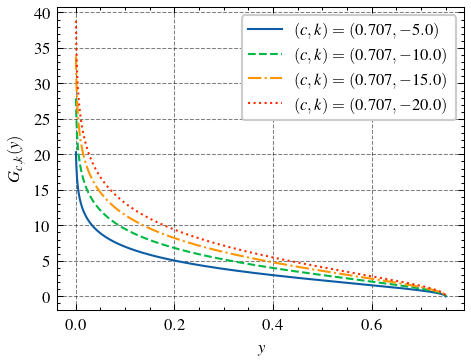

In [3]:
### Varying k ###

N = 5
c = np.sqrt(2)/2
ks = -np.linspace(0, 20, N)[1:]
print("c =", c, "k =", ks)

y_to_plot = np.linspace(0, 1-c*c/2, 1_000)

for k in ks:
    plt.plot(y_to_plot, G_c_k(y_to_plot, c, k), label=r"$(c, k)={}$".format((round(c, 3), round(k, 3))),
            marker="none")
    plt.legend()

plt.xlabel(r"$y$")
plt.ylabel(r"$G_{c, k}(y)$")

plt.savefig(path_save+"Func_to_inv_ks.pdf", dpi=300, bbox_inches = "tight")
plt.savefig(path_save+"Func_to_inv_ks.pgf", dpi=300, bbox_inches = "tight")
plt.show()

c = [0.         0.28284271 0.56568542 0.84852814 1.13137085] k = -10


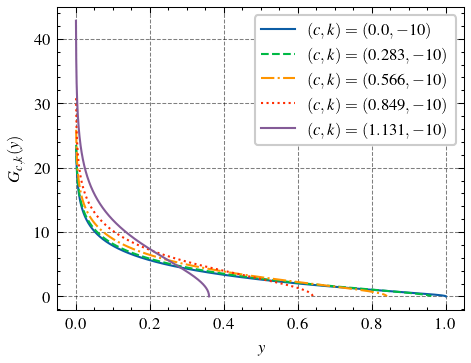

In [4]:
### Varying c ###

N = 5
cs = np.linspace(0, np.sqrt(2), N, endpoint=False)
k = -10
print("c =", cs, "k =", k)

for c in cs:
    y_to_plot = np.linspace(0, 1-c*c/2, 1_000)[1:]
    plt.plot(y_to_plot, G_c_k(y_to_plot, c, k), label=r"$(c, k)={}$".format((round(c, 3), round(k, 3))),
            marker="none")
    plt.legend()
    
plt.xlabel(r"$y$")
plt.ylabel(r"$G_{c, k}(y)$")

plt.savefig(path_save+"Func_to_inv_cs.pdf", dpi=300, bbox_inches = "tight")
plt.savefig(path_save+"Func_to_inv_cs.pgf", dpi=300, bbox_inches = "tight")
plt.show()

## Dark soliton

In [5]:
def _get_valid_refpoints(xmin, xmax):
    d = xmax - xmin
    ref1 = xmin + d / 4.
    ref2 = xmax - d / 4.
    return ref1, ref2

In [6]:
import warnings

## eta_c_k generator

def etaG_c_k(x, c, k, even=True):
    
    # Domain
    ymin = 0
    ymax = 1-(c*c/2)
    
    ref1, ref2 = _get_valid_refpoints(ymin, ymax)
    
    min_kwargs = {}
    min_kwargs['bracket'] = (ref1, ref2)
    min_kwargs['tol'] = 1.48e-12
    min_kwargs['method'] = 'Golden'
    
    x = np.asarray(x)
    N = x.size
    m = N//2
    
    xpos = x[N//2:]
    
    F_to_inv = lambda y: G_c_k(y, c, k)
    
    results = np.full_like(x, np.nan, dtype=np.float64)
    resultsmask = np.zeros(x. shape, dtype=bool)
    
    for j in range(xpos.size):
        
        if F_to_inv(ymax) == xpos[j]: #is_close
            results[N//2+j] = ymax
        
        if F_to_inv(ymin) == xpos[j]:
            results[N//2+j] = ymin
        
        optimizer = (lambda x, j=j,
                        bounded_f=F_to_inv: (np.abs(F_to_inv(x) - xpos[j]))**2)
        
        try:
            with warnings.catch_warnings(record=True):
                result = minimize_scalar(optimizer, **min_kwargs)

            results[N//2+j] = result.x
            resultsmask[N//2+j] = result.success

        except:
            resultsmask[N//2+j] = False

    if any(~resultsmask[N//2:]):
            warnings.warn("Trouble calculating inverse for values: "
                          "%s" % str(xpos[~resultsmask[N//2:]]), RuntimeWarning)   
    try:
        np.testing.assert_array_almost_equal(xpos, F_to_inv(results[N//2:]), decimal=2)

    except AssertionError:
        warnings.warn("Results obtained with less than %g "
                          "decimal digits of accuracy"
                          % 2, RuntimeWarning)

    if even:
        if N%2 == 0:
            results[:N//2] = np.flip(results[N//2:])
        else:
            results[:N//2] = np.flip(results[N//2+1:])
        return results
    
    return results[N//2:]


c = 0.7071067811865476 k = [ -5. -10. -15. -20.]


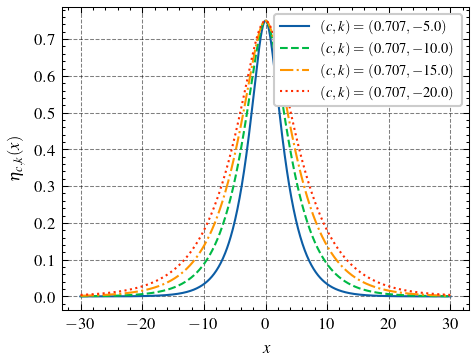

In [7]:
#import warnings
#warnings.filterwarnings("ignore")

### Invert function ###

### Varying k ###

N = 5
c = np.sqrt(2)/2
ks = -np.linspace(0, 20, N)[1:]
print("c =", c, "k =", ks)

L = 30
x = np.linspace(-L, L, 1_001)

for k in ks:
    
    plt.plot(x, etaG_c_k(x, c, k), label=r"$(c, k)={}$".format((round(c, 3), round(k, 3))),
             marker="none")
    plt.legend(fontsize=7)

plt.xlabel(r"$x$")
plt.ylabel(r"$\eta_{c, k}(x)$")

plt.savefig(path_save+"eta_ks.pdf", dpi=300, bbox_inches = "tight")
plt.savefig(path_save+"eta_ks.pgf", dpi=300, bbox_inches = "tight")
plt.show()

In [17]:
print("c = ", c, "k = ", k)
Ns = np.array([2**(j) for j in range(2, 11)])
hs = []
errors = [] #np.zeros(len(Ns))
xs = []
L = 5

for j in range(len(Ns)):
    N = Ns[j]
    x = np.linspace(-L, L, N)
    eta = etaG_c_k(x, c, k, even=False)
    
    x_pos = x[N//2:]
    h = x_pos[1] - x_pos[0]
    hs += [h]
    F_eta = G_c_k(eta, c, k)
    error = np.abs(x_pos - F_eta)
    
    errors += [error]
    xs += [x_pos]
    
hs = np.array(hs)

c =  0.7071067811865476 k =  -20.0


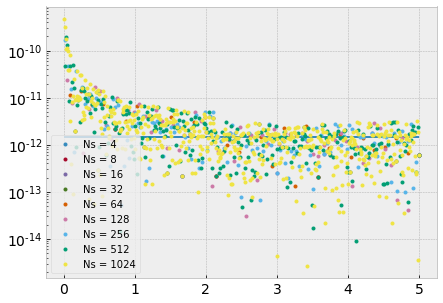

In [18]:
for j in range(len(errors)):
    plt.plot(xs[j], errors[j], ".", label="Ns = {}".format(Ns[j]))
#plt.plot(hs, hs**-0.8 * np.exp(-28))
plt.legend(fontsize=10)
plt.hlines(1.48e-12, 0, 5)
plt.yscale("log")
#plt.xscale("log")
plt.show()

In [20]:
print("c = ", c, "k = ", k)
Ns = np.array([2**(j) for j in range(2, 11)])
hs = []
errors = [] #np.zeros(len(Ns))
ys = []
L = 5

for j in range(len(Ns)):
    N = Ns[j]
    y = np.linspace(0, 1-c*c/2, N)[1:]
    F_ = G_c_k(y, c, k)
    F_ = np.append(np.flip(F_), F_)
    eta = etaG_c_k(F_, c, k, even=False)
    error = np.abs(y - eta)
    
    errors += [error]
    ys += [y]
    
hs = np.array(hs)

c =  0.7071067811865476 k =  -20.0


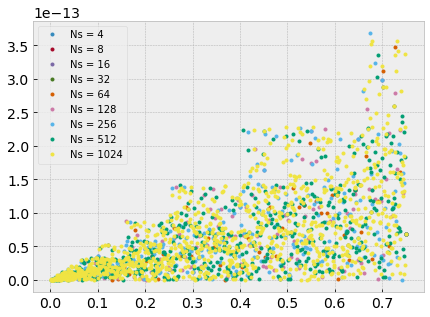

In [21]:
for j in range(len(errors)):
    plt.plot(ys[j], errors[j], ".", label="Ns = {}".format(Ns[j]))
#plt.plot(hs, hs**-0.8 * np.exp(-28))
plt.legend(fontsize=10)
#plt.hlines(1.48e-12, 0, 5)
#plt.yscale("log")
#plt.xscale("log")
plt.show()

c = [0.         0.35355339 0.70710678 1.06066017] k = -5


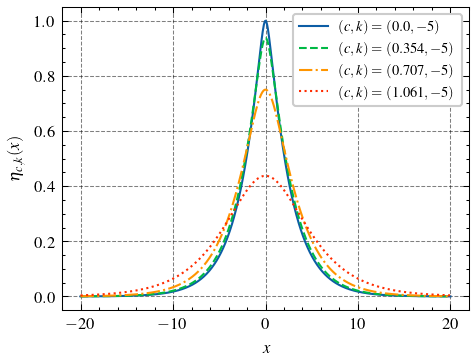

In [45]:
### Varying c ###

N = 4
cs = np.linspace(0, np.sqrt(2), N, endpoint=False)
k = -5
print("c =", cs, "k =", k)

L = 20
x = np.linspace(-L, L, 1_000)

for c in cs:
    
    plt.plot(x, etaG_c_k(x, c, k), label=r"$(c, k)={}$".format((round(c, 3), round(k, 3))), 
            marker="none")
    plt.legend(fontsize=7)

plt.xlabel(r"$x$")
plt.ylabel(r"$\eta_{c, k}(x)$")

plt.savefig(path_save+"eta_cs.pdf", dpi=300, bbox_inches = "tight")
plt.savefig(path_save+"eta_cs.pgf", dpi=300, bbox_inches = "tight")
plt.show()

## Checking ODE $\eta$ 

In [42]:
from numpy.linalg import norm as L2_norm

#P'(c)
def P_p(c, k):
    sqrt = np.sqrt((1 - 2 * k)/(2 - c**2))
    frac = (3 * c**2 * k - 4 * k - 1)/(4 * np.sqrt(-k))
    
    sum_1 = frac * np.arctanh(np.sqrt(-k)/sqrt)
    sum_2 = 3 * (2 - c**2)/4 * sqrt
    output = sum_1 - sum_2
    return output

#P''(c)
def P_pp(c, k):
    frac = 6 * c * k/(4 * np.sqrt(-k))
    sqrt = np.sqrt((1 - 2 * k)/(2 - c**2))
    sum_1 = frac * np.arctanh(np.sqrt(-k)/sqrt)
    
    frac_2 = (3 * c**2 * k - 4 * k - 1)/4
    sum_2 = frac_2 * sqrt * c/(1 - k * c**2) + 3/4 * c * sqrt
    output = sum_1 - sum_2
    return output

def newton_1D(x_0, f, f_prime, tol=1e-8):
    x_k = x_0
    error = np.add.reduce(np.abs(f(x_k)))
    while error > tol:
        f_1 = -f(x_k)
        f_2 = f_prime(x_k)
        delta_x = f_1/f_2
        x_k_1 = x_k + delta_x
        error = L2_norm([x_k - x_k_1], ord=2) #np.add.reduce(np.abs(f(x_k)))
        x_k = x_k_1

    if error != error:
        return 0, 1

    return x_k, error

In [87]:
c_0 = np.sqrt(2)/2
k = -20

P_p_ = lambda c: P_p(c, k)
P_pp_ = lambda c: P_pp(c, k)

c_star, error = newton_1D(c_0, P_p_, P_pp_)
c = c_star - 0.1

L = 60
x = np.linspace(-L, L, 20_000)
h = x[1] - x[0]

eta = etaG_c_k(x, c, k)
eta_prime = np.gradient(eta, h)
eta_prime_prime = np.gradient(eta_prime, h)

ODE = (1 - 2 * k + 2 * k * eta) * eta_prime_prime + k * eta_prime**2 + 3 * eta**2 - (2-c**2) * eta
ODE_2 = (1 - 2 * k + 2 * k * eta) * eta_prime**2 - (2 - c**2 - 2 * eta) * eta**2

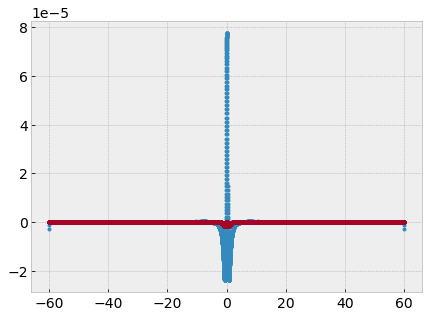

In [88]:
plt.plot(x, ODE, ".")
plt.plot(x, ODE_2, ".")

## $u$ variable

In [46]:
## Solitons in variable u

def rho_c_k(x, eta):
    output = np.sqrt(1 - eta)
    return output
    

def theta_c_k(x, c, eta):
    
    ## Function to integrate
    integrand = eta/(1 - eta)
    
    N = x.size
    m = N//2
    xpos = x[m:]
    theta = np.zeros(N)
    
    dx = xpos[1] - xpos[0]

    for j in range(xpos.size-1):
        
        theta[j+1+m] = theta[j+m] + c/2 * (dx/2 * (integrand[j+m] + integrand[j+m+1]))
    
    theta[:m] = -np.flip(theta[m+1:])
    
    return theta


def u_c_k(x, c, eta):
    i = 1j
    
    if c == 0:
        output = np.sign(x) * np.sqrt(1 - eta)
        return output
    
    rho = rho_c_k(x, eta)
    theta = theta_c_k(x, c, eta)
    return rho * np.exp(i*theta)

def norm(x):
    return np.abs(x)**2

c = 0.7071067811865476 k = [ -2.5  -5.   -7.5 -10. ]


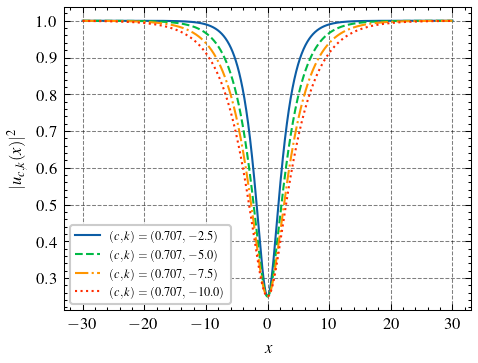

In [56]:
### Varying k ###

N = 5
c = np.sqrt(2)/2 #0
ks = -np.linspace(0, 10, N)[1:]
print("c =", c, "k =", ks)


L = 30
x = np.linspace(-L, L, 2_001)


for k in ks:
    eta = etaG_c_k(x, c, k)
    plt.plot(x, norm(u_c_k(x, c, eta)), label=r"$(c, k)={}$".format((round(c, 3), round(k, 3))),
            marker="none")
    plt.legend(fontsize=6)

plt.xlabel(r"$x$")
plt.ylabel(r"$|u_{c, k}(x)|^2$")

plt.savefig(path_save+"D2_Dark_soliton_ks.pdf", dpi=300, bbox_inches = "tight")
plt.savefig(path_save+"D2_Dark_soliton_ks.pgf", dpi=300, bbox_inches = "tight")
plt.show()

c = [0.         0.35355339 0.70710678 1.06066017] k = -5


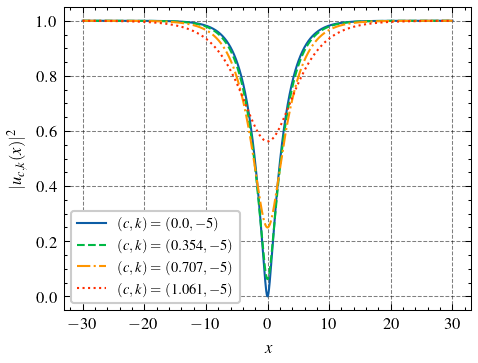

In [54]:
### Varying c ###

N = 4
cs = np.linspace(0, np.sqrt(2), N, endpoint=False)
k = -5
print("c =", cs, "k =", k)

L = 30
x = np.linspace(-L, L, 2_001)

for c in cs:
    eta = etaG_c_k(x, c, k)
    plt.plot(x, norm(u_c_k(x, c, eta)), label=r"$(c, k)={}$".format((round(c, 3), round(k, 3))),
            marker="none")
    plt.legend(fontsize=7)

plt.xlabel(r"$x$")
plt.ylabel(r"$|u_{c, k}(x)|^2$")

plt.savefig(path_save+"D2_Dark_soliton_cs.pdf", dpi=300, bbox_inches = "tight")
plt.savefig(path_save+"D2_Dark_soliton_cs.pgf", dpi=300, bbox_inches = "tight")
plt.show()

## ODE $\theta$

In [77]:
c_0 = np.sqrt(2)/2
k = -50

P_p_ = lambda c: P_p(c, k)
P_pp_ = lambda c: P_pp(c, k)

c, error = newton_1D(c_0, P_p_, P_pp_)

L = 80
x = np.linspace(-L, L, 10_001)
h = x[1] - x[0]

eta = etaG_c_k(x, c, k)

theta = theta_c_k(x, c, eta)
theta_prime = np.gradient(theta, h, edge_order=2)
i = 1j

ODE_theta = theta_prime - c/2 * eta/(1 - eta)

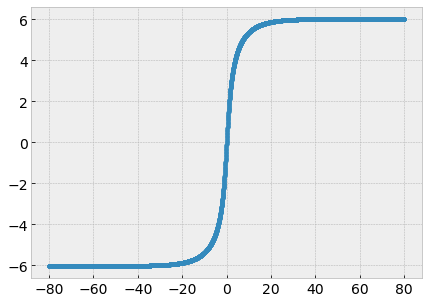

In [78]:
plt.plot(x, theta, ".")

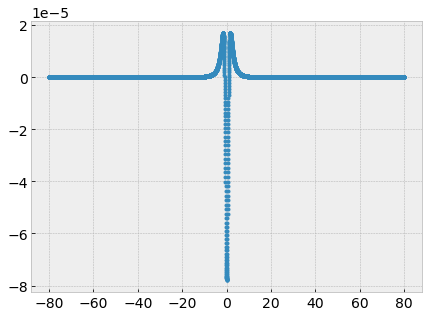

In [79]:
plt.plot(x, ODE_theta, ".")

## ODE $u$

In [73]:
c = np.sqrt(2)/2
k = 1/4

L = 10
x = np.linspace(-L, L, 10_000)
h = x[1] - x[0]

eta = eta_c_k(x, c, k)

u = u_c_k(x, c, eta)
u_prime = np.gradient(u, h)
u_prime_prime = np.gradient(u_prime, h)
norm_prime = np.gradient(1-np.abs(u)**2, h)
norm_prime_prime = np.gradient(norm_prime, h)
i = 1j

ODE_u = i * c * u_prime + u_prime_prime + u * (1 - np.abs(u)**2) + k * u * norm_prime_prime

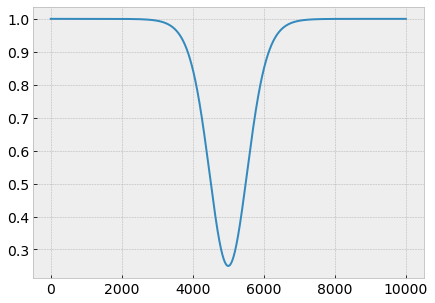

In [75]:
plt.plot(norm(u))

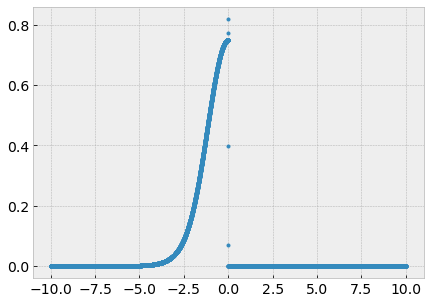

In [76]:
plt.plot(x, np.real(ODE_u), ".")

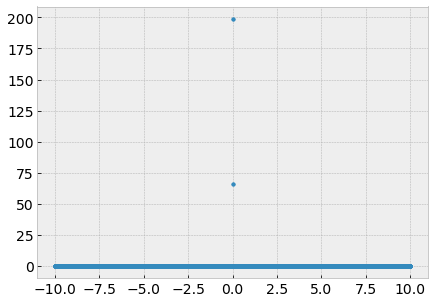

In [77]:
plt.plot(x, np.imag(ODE_u), ".")

# Anti-Dark Solitons in $D_3$

In [59]:
path_save = "Solitons/Antidark/"
# Function to invert
def H_c_k(y, c, k):
    
    # Domain
    ymin = 1-c*c/2
    ymax = 0
    
    y = np.asarray(y)
    
    valid_mask = (y >= ymin) & (y < ymax)
    
    # Assign infinite to values outside the domain
    val = np.full_like(y, -np.inf, dtype=np.float64)
    val[y > ymax] = np.inf
    
    def h_c_k(y):
        root = np.sqrt((2-c*c-2*y)/(1-2*k+2*k*y))
        sum_1 = 2 * np.sqrt(k) * np.arctan(np.sqrt(k) * root)
        sum_2 = 2 * np.sqrt((1-2*k)/(2-c*c)) * np.arctanh(np.sqrt((1-2*k)/(2-c*c)) * root)
        output = sum_1 + sum_2
        return output
    
    val[valid_mask] = h_c_k(y[valid_mask])
    
    return val

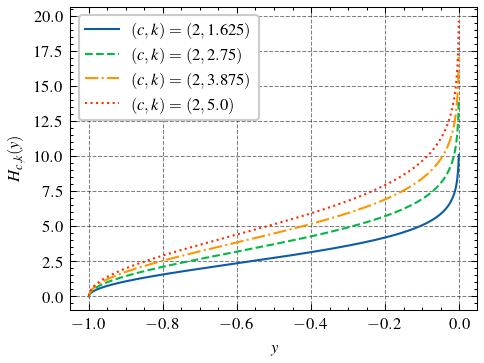

In [60]:
### Varying k ###

N = 5
c = 2
ks = np.linspace(1/2, 5, N)[1:]
#print("c =", c, "k =", ks)

y_to_plot = np.linspace(1-c*c/2, 0, 1_000, endpoint=False)

for k in ks:
    plt.plot(y_to_plot, H_c_k(y_to_plot, c, k), label=r"$(c, k)={}$".format((round(c, 3), round(k, 3))),
            marker="none")
    plt.legend()
    
plt.xlabel(r"$y$")
plt.ylabel(r"$H_{c, k}(y)$")

plt.savefig(path_save+"Func_to_inv_ks.pdf", dpi=300, bbox_inches = "tight")
plt.savefig(path_save+"Func_to_inv_ks.pgf", dpi=300, bbox_inches = "tight")
plt.show()

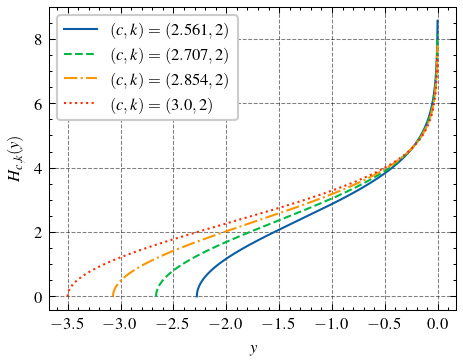

In [72]:
### Varying c ###

N = 5
cs = np.linspace(1+np.sqrt(2), 3, N)[1:]
k = 2
#print("c =", cs, "k =", k)

for c in cs:
    y_to_plot = np.linspace(1-c*c/2, 0, 1_000, endpoint=False)
    plt.plot(y_to_plot, H_c_k(y_to_plot, c, k), label=r"$(c, k)={}$".format((round(c, 3), round(k, 3))),
            marker="none")
    plt.legend()
    
plt.xlabel(r"$y$")
plt.ylabel(r"$H_{c, k}(y)$")
plt.savefig(path_save+"Func_to_inv_cs.pdf", dpi=300, bbox_inches = "tight")
plt.savefig(path_save+"Func_to_inv_cs.pgf", dpi=300, bbox_inches = "tight")
plt.show()

## Antidark soliton

In [65]:
## eta_c_k generator

def eta_H_c_k(x, c, k, even=True):
    
    # Domain
    ymin = 1-c*c/2
    ymax = 0
    
    ref1, ref2 = _get_valid_refpoints(ymin, ymax)
    
    min_kwargs = {}
    min_kwargs['bracket'] = (ref1, ref2)
    min_kwargs['tol'] = 1.48e-12
    min_kwargs['method'] = 'Golden'
    
    x = np.asarray(x)
    N = x.size
    m = N//2
    
    if N == 1:
        xpos = x
        
    else:
        xpos = x[N//2:]
    
    H_to_inv = lambda y: H_c_k(y, c, k)
    
    results = np.full_like(x, np.nan, dtype=np.float64)
    
    for j in range(xpos.size):
        
        if H_to_inv(ymax) == xpos[j]:
            results[N//2+j] = ymax
        
        if H_to_inv(ymin) == xpos[j]:
            results[N//2+j] = ymin
        
        optimizer = (lambda x, j=j,
                        bounded_f=H_to_inv: (np.abs(H_to_inv(x) - xpos[j]))**2)
        
        result = minimize_scalar(optimizer, **min_kwargs)
        results[N//2+j] = result.x
    
    if N%2 == 0:
        results[:m] = np.flip(results[m:])
    else:
        results[:m] = np.flip(results[m+1:])
        
    return results

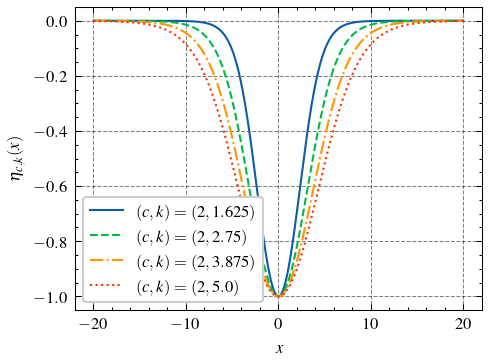

In [66]:
import warnings
#warnings.filterwarnings("ignore")

### Invert function ###

### Varying k ###

N = 5
c = 2
ks = np.linspace(1/2, 5, N)[1:]
#print("c =", c, "k =", ks)

L = 20
x = np.linspace(-L, L, 1_000)


for k in ks:
    
    plt.plot(x, eta_H_c_k(x, c, k), label=r"$(c, k)={}$".format((round(c, 3), round(k, 3))),
            marker="none")
    plt.legend()

plt.xlabel(r"$x$")
plt.ylabel(r"$\eta_{c, k}(x)$")

plt.savefig(path_save+"eta_ks.pdf", dpi=300, bbox_inches = "tight")
plt.savefig(path_save+"eta_ks.pgf", dpi=300, bbox_inches = "tight")
plt.show()

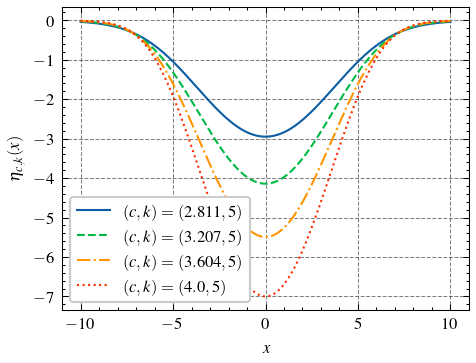

In [71]:
### Varying c ###

N = 5
cs = np.linspace(1+np.sqrt(2), 4, N)[1:]
k = 5
#print("c =", cs, "k =", k)

L = 10
x = np.linspace(-L, L, 1_000)
xs = x[len(x)//2:]

for c in cs:
    
    plt.plot(x, eta_H_c_k(x, c, k), label=r"$(c, k)={}$".format((round(c, 3), round(k, 3))),
            marker="none")
    plt.legend()

plt.xlabel(r"$x$")
plt.ylabel(r"$\eta_{c, k}(x)$")

plt.savefig(path_save+"eta_cs.pdf", dpi=300, bbox_inches = "tight")
plt.savefig(path_save+"eta_cs.pgf", dpi=300, bbox_inches = "tight")
plt.show()

## Checking ODE $\eta$ 

In [42]:
c = 2
k = 5

L = 40
x = np.linspace(-L, L, 10_001)
h = x[1] - x[0]

eta = eta_H_c_k(x, c, k)
eta_prime = np.gradient(eta, h)
eta_prime_prime = np.gradient(eta_prime, h)

ODE = (1 - 2 * k + 2 * k * eta) * eta_prime_prime + k * eta_prime**2 + 3 * eta**2 - (2-c**2) * eta
ODE_2 = (1 - 2 * k + 2 * k * eta) * eta_prime**2 - (2 - c**2 - 2 * eta) * eta**2

ValueError: could not broadcast input array from shape (5001,) into shape (5000,)

In [ ]:
plt.plot(x, ODE, ".")
plt.plot(x, ODE_2, ".")

In [357]:
c, k = 2, 5
print("c = ", c, "k = ", k)
Ns = np.array([2**(j) for j in range(2, 11)])
hs = []
errors = [] #np.zeros(len(Ns))
xs = []
L = 20

for j in range(len(Ns)):
    N = Ns[j]
    x = np.linspace(-L, L, N)
    eta = eta_H_c_k(x, c, k, even=False)
    
    x_pos = x[N//2:]
    h = x_pos[1] - x_pos[0]
    hs += [h]
    F_eta = H_c_k(eta, c, k)
    error = np.abs(x_pos - F_eta)
    
    errors += [error]
    xs += [x_pos]
    
hs = np.array(hs)

c =  2 k =  5


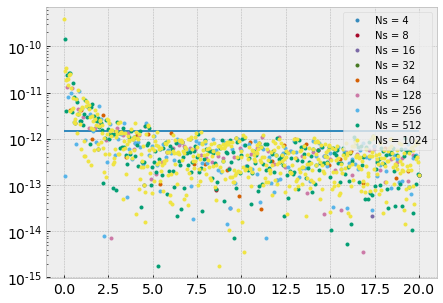

In [358]:
for j in range(len(errors)):
    plt.plot(xs[j], errors[j], ".", label="Ns = {}".format(Ns[j]))
#plt.plot(hs, hs**-0.8 * np.exp(-28))
plt.legend(fontsize=10)
plt.hlines(1.48e-12, 0, 20)
plt.yscale("log")
#plt.xscale("log")
plt.show()

In [367]:
print("c = ", c, "k = ", k)
Ns = np.array([2**(j) for j in range(2, 11)])
hs = []
errors = [] #np.zeros(len(Ns))
ys = []
L = 20

for j in range(len(Ns)):
    N = Ns[j]
    y = np.linspace(1-c*c/2, 0, N, endpoint=False)
    F_ = H_c_k(y, c, k)
    F_ = np.append(np.flip(F_), F_)
    eta = eta_H_c_k(F_, c, k, even=False)
    error = np.abs(y - eta)

    errors += [error]
    ys += [y]

hs = np.array(hs)

c =  2 k =  5


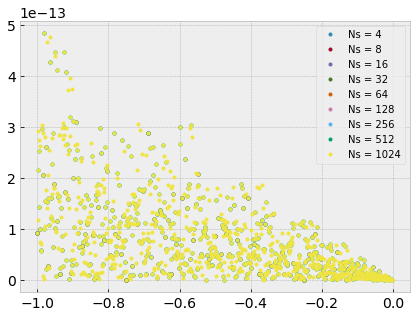

In [368]:
for j in range(len(errors)):
    plt.plot(ys[j], errors[j], ".", label="Ns = {}".format(Ns[j]))
#plt.plot(hs, hs**-0.8 * np.exp(-28))
plt.legend(fontsize=10)
#plt.hlines(1.48e-12, 0, 5)
#plt.yscale("log")
#plt.xscale("log")
plt.show()

## $u$ variable

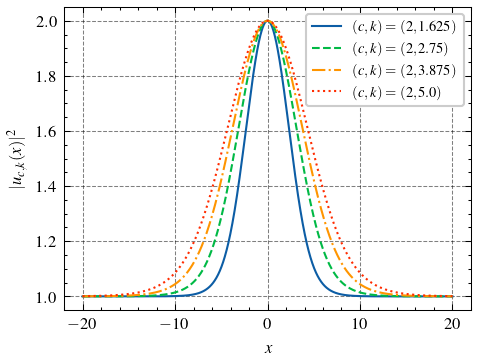

In [73]:
### Varying k ###

N = 5
c = 2
ks = np.linspace(1/2, 5, N)[1:]
#print("c =", c, "k =", ks)


L = 20
x = np.linspace(-L, L, 2_001)


for k in ks:
    eta = eta_H_c_k(x, c, k)
    plt.plot(x, norm(u_c_k(x, c, eta)), label=r"$(c, k)={}$".format((round(c, 3), round(k, 3))),
            marker="none")
    plt.legend(fontsize=7)

plt.xlabel(r"$x$")
plt.ylabel(r"$|u_{c, k}(x)|^2$")

plt.savefig(path_save+"D3_antidark_soliton_ks.pdf", dpi=300, bbox_inches = "tight")
plt.savefig(path_save+"D3_antidark_soliton_ks.pgf", dpi=300, bbox_inches = "tight")
plt.show()

c = [2.81066017 3.20710678 3.60355339 4.        ] k = 2


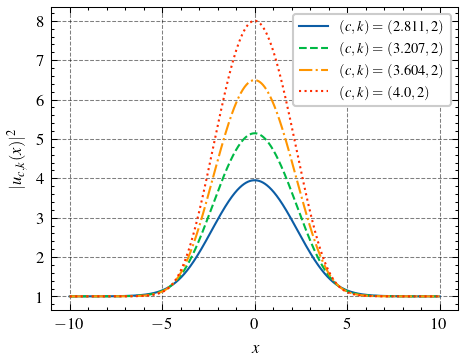

In [77]:
### Varying c ###

N = 5
cs = np.linspace(1+np.sqrt(2), 4, N)[1:]
k = 2
print("c =", cs, "k =", k)

L = 10
x = np.linspace(-L, L, 2001)

for c in cs:

    eta = eta_H_c_k(x, c, k)
    plt.plot(x, norm(u_c_k(x, c, eta)), label=r"$(c, k)={}$".format((round(c, 3), round(k, 3))),
            marker="none")
    plt.legend(fontsize=7)

plt.xlabel(r"$x$")
plt.ylabel(r"$|u_{c, k}(x)|^2$")

plt.savefig(path_save+"D3_antidark_soliton_cs.pdf", dpi=300, bbox_inches = "tight")
plt.savefig(path_save+"D3_antidark_soliton_cs.pgf", dpi=300, bbox_inches = "tight")
plt.show()


# Bright Solitons

In [6]:
path_save = "Solitons/bright/"
# Function to invert

    
def Fb_c_k(y, w, k):
    
    # Domain
    ymin = 0
    ymax = np.sqrt(2*w)
    
    y = np.asarray(y)
    
    valid_mask = (y > ymin) & (y < ymax)
    
    # Assign infinite to values outside the domain
    val = np.full_like(y, -np.inf, dtype=np.float64)
    val[y > ymax] = np.inf

    def f_w_k(y):
        root = np.sqrt((2*w - y*y)/(1+2*k*y*y))
        sum_1 = 1 / np.sqrt(w) * np.arctanh(1/np.sqrt(2*w) * root)
        sum_2 = 2 * np.sqrt(k) * np.arctan(np.sqrt(2*k) * root)
        output = sum_1 + sum_2

        return output
    
    val[valid_mask] = f_w_k(y[valid_mask])
    
    return val

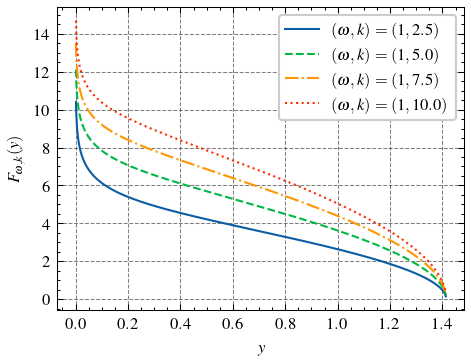

In [13]:
### Varying k ###

N = 5
w = 1
ks = np.linspace(0, 10, N)[1:]
#print("c =", c, "k =", ks)

y_to_plot = np.linspace(0, np.sqrt(2*w), 1_000, endpoint=False)

for k in ks:
    plt.plot(y_to_plot, Fb_c_k(y_to_plot, w, k), label=r"$(\omega, k)={}$".format((round(w, 3), round(k, 3))),
            marker="none")
    plt.legend()
    
plt.xlabel(r"$y$")
plt.ylabel(r"$F_{\omega, k}(y)$")

plt.savefig(path_save+"Func_to_inv_ks.pdf", dpi=300, bbox_inches = "tight")
plt.savefig(path_save+"Func_to_inv_ks.pgf", dpi=300, bbox_inches = "tight")
plt.show()

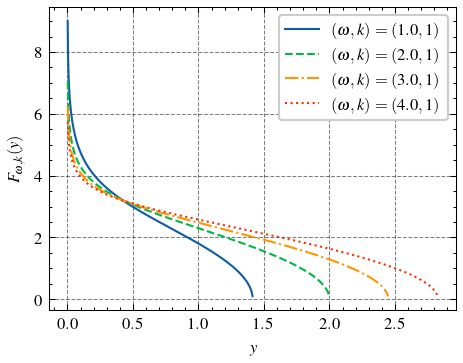

In [14]:
### Varying k ###

N = 5
k = 1
ws = np.linspace(0, 4, N)[1:]
#print("c =", c, "k =", ks)

for w in ws:
    y_to_plot = np.linspace(0, np.sqrt(2*w), 1_000, endpoint=False)
    plt.plot(y_to_plot, Fb_c_k(y_to_plot, w, k), label=r"$(\omega, k)={}$".format((round(w, 3), round(k, 3))),
            marker="none")
    plt.legend()
    
plt.xlabel(r"$y$")
plt.ylabel(r"$F_{\omega, k}(y)$")

plt.savefig(path_save+"Func_to_inv_ws.pdf", dpi=300, bbox_inches = "tight")
plt.savefig(path_save+"Func_to_inv_ws.pgf", dpi=300, bbox_inches = "tight")
plt.show()

In [8]:
## eta_c_k generator

def eta_Fb_c_k(x, w, k, even=True):
    
    # Domain
    ymin = 0
    ymax = np.sqrt(2*w)
    
    ref1, ref2 = _get_valid_refpoints(ymin, ymax)
    
    min_kwargs = {}
    min_kwargs['bracket'] = (ref1, ref2)
    min_kwargs['tol'] = 1.48e-12
    min_kwargs['method'] = 'Golden'
    
    x = np.asarray(x)
    N = x.size
    m = N//2
    
    if N == 1:
        xpos = x
        
    else:
        xpos = x[N//2:]
    
    H_to_inv = lambda y: Fb_c_k(y, w, k)
    
    results = np.full_like(x, np.nan, dtype=np.float64)
    
    for j in range(xpos.size):
        
        if H_to_inv(ymax) == xpos[j]:
            results[N//2+j] = ymax
        
        if H_to_inv(ymin) == xpos[j]:
            results[N//2+j] = ymin
        
        optimizer = (lambda x, j=j,
                        bounded_f=H_to_inv: (np.abs(H_to_inv(x) - xpos[j]))**2)
        
        result = minimize_scalar(optimizer, **min_kwargs)
        results[N//2+j] = result.x
    
    if N%2 == 0:
        results[:m] = np.flip(results[m:])
    else:
        results[:m] = np.flip(results[m+1:])
        
    return results

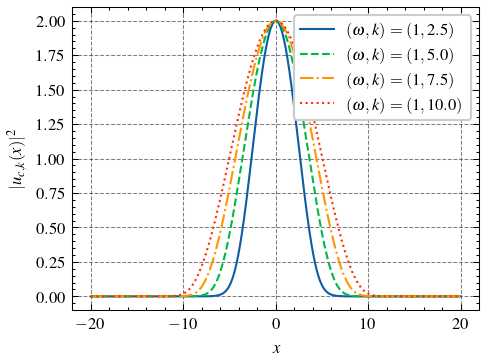

In [12]:
import warnings
#warnings.filterwarnings("ignore")

### Invert function ###

### Varying k ###

N = 5
w = 1
ks = np.linspace(0, 10, N)[1:]
#print("c =", c, "k =", ks)

L = 20
x = np.linspace(-L, L, 1_000)

for k in ks:
    
    plt.plot(x, norm(eta_Fb_c_k(x, w, k)), label=r"$(\omega, k)={}$".format((round(w, 3), round(k, 3))),
            marker="none")
    plt.legend()

plt.xlabel(r"$x$")
plt.ylabel(r"$|u_{c, k}(x)|^2$")

plt.savefig(path_save+"Bright_soliton_ks.pdf", dpi=300, bbox_inches = "tight")
plt.show()

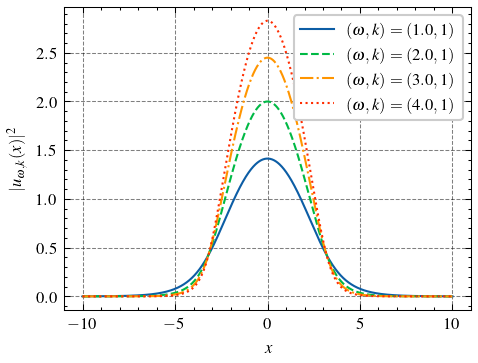

In [116]:
import warnings
#warnings.filterwarnings("ignore")

### Invert function ###

### Varying k ###

N = 5
k = 1
ws = np.linspace(0, 4, N)[1:]
#print("c =", c, "k =", ks)

L = 10
x = np.linspace(-L, L, 1_000)

for w in ws:
    plt.plot(x, eta_Fb_c_k(x, c, k), label=r"$(\omega, k)={}$".format((round(w, 3), round(k, 3))),
            marker="none")
    plt.legend()

plt.xlabel(r"$x$")
plt.ylabel(r"$|u_{\omega, k}(x)|^2$")

plt.savefig(path_save+"Bright_soliton_ws.pdf", dpi=300, bbox_inches = "tight")
plt.savefig(path_save+"Bright_soliton_ws.pgf", dpi=300, bbox_inches = "tight")
plt.show()